# Moderate Wide-Angle Lens Optimization — constrained numerical benchmark

[Optiland competition](https://www.optiland.org/competitions), ID `d0d73808-3180-4ca2-b91e-e1d71cd79a86`.

This frozen six-element spherical N-BK7/F2 design is a **nominal validation case with poor image quality**, not a competitive or fabrication-ready lens. Its self-created weak-singlet seed was conditioned locally; no private prescription or public gallery lens was used for the accepted design. A rejected gallery initialization was not retained.

The local definition is `sum_fields[(distortion_fraction / 0.02)^2 + (1 - mean(MTF_S, MTF_T))^2] + P`, with field weights one. The spectrum is exactly 486/588/656 nm, equally weighted, and the same fixed image plane is used for all fields and colors. Distortion uses the 588 nm chief height divided by `EFL_588 * tan(field)` minus one, with zero declared on-axis. The denominator 0.02 is a 2% scale, **not a hard distortion limit**. The public rules do not specify axis reduction, field-weight magnitudes, detailed MTF method or P; this is an explicit local interpretation, not an official score.

The final target calculation is a **scalar normalized entrance-pupil approximation at exactly 20 lp/mm**, using native Optiland optical paths and continuous shifted-pupil overlap. Complex spectral OTFs are averaged before magnitude; the arithmetic mean of the two resulting axis magnitudes enters the score. Both axes remain visible. A physical planar air stop at the front has EPD 6 mm and fixed radius 3 mm; it is never widened to hide vignetting. Numerical aperture-boundary tolerance 1e-9 mm matches the original standalone tracer, without altering physical radii.

**Limits remain visible:** edge MTF is very low, off-axis chief angles reach about 31 degrees, and the scalar approximation does not certify full physical diffraction. The individual pupil phase is undersampled for a complete FFT/PSF at the final grid. The exact-20 overlap integrand and its density sensitivity are checked separately; no full PSF or complete MTF-curve accuracy is claimed. No coatings, polarization, thermal, tolerance or assembly analysis is certified.


In [1]:
import importlib.metadata, importlib.util, subprocess, sys

# Pin the exact public source revision used for the independent Optiland check.
revision = 'a9e544a2e058f1c1b64606e9ce90e6dc103efee1'
installed = importlib.metadata.version('optiland') if importlib.util.find_spec('optiland') else ''
if 'ga9e544a2' not in installed:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'git+https://github.com/optiland/optiland.git@' + revision])

import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optiland.backend as be
from optiland.materials import Material, IdealMaterial
from optiland.materials.material_spec import MatchPolicy
from optiland.optic import Optic
from optiland.physical_apertures import RadialAperture
from optiland.rays import RealRays
be.set_backend('numpy')
print('Optiland:', importlib.metadata.version('optiland'))
print('NumPy:', np.__version__)


Optiland: 0.6.2.post234+ga9e544a2
NumPy: 2.3.5


## Bounded optimization and original-source CPU/CUDA reproduction

Self-created five- and six-element positive/crown-flint seed branches were checked. SciPy bounded least-squares first conditioned real-ray RMS, then an explicitly **geometric** complex ray-characteristic-function proxy at 20 lp/mm and distortion. That geometric proxy was training only; final selection uses the scalar diffraction definition above. Search allocations were CT 2.05–15 mm, variable internal air distances 0.05–25 mm, BFD 12.1–60 mm and spherical curvature within 98.5% of the starting mechanical-domain bound. Mechanical apertures were recomputed from all sampled colors/fields plus 96 circumference probes and a declared 0.15 mm radial allocation, while the stop remained exactly 3 mm. These allocations are local nominal constraints, not manufacturing certification or added official rules. Local branches were bounded and stopped at their budget or step criterion; no global optimum is asserted.

The next cell freshly runs the unchanged standalone-optics candidate generator, 4-worker CPU and optional actual CUDA coarse screen, serial comparison and CPU 20x64 dense replay of eight finalists plus baseline. It uses 15 curvature candidates, surfaces 2/7/12 and actual perturbation bounds ±2e-5 mm^-1. WFE ranking and the final contest objective are different: the source WFE winner was rejected using the independent 512-grid discrete-lag/FFT local-objective comparison (approximately 4.99405 versus 4.98261); the retained baseline is then evaluated here with the exact-frequency continuous-shift method. The eligible pre-screen baseline was retained. This narrow verification screen is not a global optimization claim. Cold startup is separate from warmed timings.


In [2]:
source_payload=json.loads(r'''{
  "commit": "d130999165abc8ccc1865c4ef145cd6bda191a4d",
  "files": {
    "scripts/ai_zemax/__init__.py": "bded78d0cee5a6d576ad22817032e8d5eb32903f0683633c5e9b117c3015d7d5",
    "scripts/ai_zemax/standalone.py": "84e8b3f11775dc8ce133067cc2f94938493ffae852edcc155cfb4408a70d8fac",
    "scripts/ai_zemax/standalone_aberrations.py": "ee2b7dd9f0fe528448e557292e2fb9179c84bcdbfcf0ed674f8914b11a5e5f52",
    "scripts/ai_zemax/standalone_analysis.py": "ec5dfabc5ee6a1670e638b4bbf2e99479e013263c6423af73557b8906916224a",
    "scripts/ai_zemax/standalone_candidate_generation.py": "fa3264316a47c0cb3a54d4a6812193e86c904c16e56b38eb2f54538dd83a3335",
    "scripts/ai_zemax/standalone_cli.py": "7aa8ee9f4796137389bd3fbc7b89715ca25cf9e2f27b7d07b254f0d05a67cc1e",
    "scripts/ai_zemax/standalone_coupled_group_search.py": "8399516b597dd6ce991ba8775e6d15560b03ae73df5117f555b7e3a6a31a0764",
    "scripts/ai_zemax/standalone_demo.py": "73b4b7cbccebc7404c41e61a12f5a22440f4821c3c2c1a46ceeffe7e8ba10cdf",
    "scripts/ai_zemax/standalone_gpu_screen.py": "60d227a0f23688288e8c368880f12e5242864519fe1487cd85f3883f59436676",
    "scripts/ai_zemax/standalone_gpu_trace.py": "3aeb0d8b234635a24fa15fae74fa90e70ffb04a2353ea673368887f1ddb3f926",
    "scripts/ai_zemax/standalone_group_search.py": "94d3b15d2f06dd0e078a56241e61c7054577d6ed58c74be816ca3fb53a19efbd",
    "scripts/ai_zemax/standalone_manufacturing.py": "97ebf815911b88bd5b0d7de99390c8ee41b8b2972aaac122b9d5ee69063a5113",
    "scripts/ai_zemax/standalone_model.py": "26c82fe38588006b28d648961aa7dc825929c917fcee5065fa86ee890a44e3fb",
    "scripts/ai_zemax/standalone_mtf.py": "4212682c206e8acb31ae9ae12d5866d1b1e70d115672056367a9f5d0ce88fce9",
    "scripts/ai_zemax/standalone_mtf_geometric.py": "1ded7cc0fd3e75a7a3fbcd06d2bee7496403fa90eaa7bc6fa44bb2489b36b28b",
    "scripts/ai_zemax/standalone_mtf_workflow.py": "9c5b3f6ce43c70fe1ce8833f9062248c045bf2cf44d4e7f3fa0d9def402c20d4",
    "scripts/ai_zemax/standalone_optimization_cli.py": "9b8a54579e0e315941bbc905cc6adeb1631e4536f3616a01040357b8d3b1bf20",
    "scripts/ai_zemax/standalone_parallel_screen.py": "13fcb1e8e9d6b44b4d5ff510e9dc51f29c00e6eeef0423d0f0c064b898c7e827",
    "scripts/ai_zemax/standalone_plots.py": "d57fba66dc57b27be954e3b7f153cb13a6a279812851f1d2c81f1fee8d5e7160",
    "scripts/ai_zemax/standalone_seed_realize.py": "f2c6330527eff290dd5543719e753e56a9864549fbc9ba06d1c9fea41fce9074",
    "scripts/ai_zemax/standalone_seed_search.py": "c5d1fe334277fe82635525d9acf9a9953ddd4af33bae4f7bcc0da00d9ed9c577",
    "scripts/ai_zemax/standalone_spot.py": "d0d8171b8acf61639585a61896ed7e061ac15f4726af0434d3fe488a806c82d0",
    "scripts/ai_zemax/standalone_system.py": "54ef9eb7963e7153976b0dc6cd0701092ca44038ea8b7f04eb9b6c645f15b0bd"
  },
  "model": {
    "vertices_mm": [
      0.0,
      0.05000000000000001,
      2.10005469873843,
      2.183186750027451,
      4.421984215424744,
      4.472025400107391,
      6.879747636394653,
      7.85224264231612,
      10.308481483496388,
      10.794001505232297,
      13.08181713347682,
      14.302759788698074,
      16.353078427184258,
      29.689529995910767
    ],
    "surface_rows": [
      {
        "curvature_mm_inv": 0.0,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 3.0,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.02860613912087555,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 3.799010624750863,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.025198085910383663,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 3.799010624750863,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.004755889123542017,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 4.465166771307759,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.0013351605143872684,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 4.465166771307759,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.01719191789819168,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 5.024582246971825,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.020063978884807078,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 5.024582246971825,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.004056377922768102,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 5.886081849268406,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.008896457715842925,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 5.886081849268406,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.008041304435307012,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 6.445991927239596,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.015149902605108897,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 6.445991927239596,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.009126439344868603,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 7.308850097339032,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.016262414278498987,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 7.308850097339032,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.0,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 16.409250023068015,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      }
    ],
    "wavelengths_um": [
      0.486,
      0.588,
      0.656
    ],
    "wavelength_weights": [
      1.0,
      1.0,
      1.0
    ],
    "indices_by_wave": [
      [
        1.0,
        1.0,
        1.522385894349391,
        1.0,
        1.6321030067298463,
        1.0,
        1.522385894349391,
        1.0,
        1.6321030067298463,
        1.0,
        1.522385894349391,
        1.0,
        1.6321030067298463,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.5167817367777037,
        1.0,
        1.6200022808636685,
        1.0,
        1.5167817367777037,
        1.0,
        1.6200022808636685,
        1.0,
        1.5167817367777037,
        1.0,
        1.6200022808636685,
        1.0,
        1.0
      ],
      [
        1.0,
        1.0,
        1.5143308473500767,
        1.0,
        1.6150484339456406,
        1.0,
        1.5143308473500767,
        1.0,
        1.6150484339456406,
        1.0,
        1.5143308473500767,
        1.0,
        1.6150484339456406,
        1.0,
        1.0
      ]
    ],
    "fields": [
      [
        0.0,
        0.0
      ],
      [
        0.0,
        10.0
      ],
      [
        0.0,
        20.0
      ],
      [
        0.0,
        30.0
      ]
    ],
    "field_weights": [
      1.0,
      1.0,
      1.0,
      1.0
    ],
    "field_unit": "deg",
    "stop_surface": 1,
    "primary_wave": 1,
    "object_at_infinity": true,
    "field_type": "angle",
    "aperture_type": "enpd",
    "aperture_value": 6.0,
    "ray_aiming": "off",
    "gaussian_apodization": 0.0
  },
  "config": {
    "candidate_count": 15,
    "random_seed": 31,
    "curvature_variables": [
      {
        "surface": 2,
        "min_delta_mm_inv": -2e-05,
        "max_delta_mm_inv": 2e-05
      },
      {
        "surface": 7,
        "min_delta_mm_inv": -2e-05,
        "max_delta_mm_inv": 2e-05
      },
      {
        "surface": 12,
        "min_delta_mm_inv": -2e-05,
        "max_delta_mm_inv": 2e-05
      }
    ],
    "screening": {
      "manufacturing_policy": {
        "schema_version": 1,
        "policy_id": "wide-angle-nominal-solids",
        "all_spherical": true,
        "sources": [
          "https://www.optiland.org/competitions"
        ],
        "notes": [
          "CT/ET minima are published; positive air/rim clearance is an additional nominal guard, not manufacturing/tolerance certification."
        ],
        "radial_samples": 1025,
        "surfaces": {
          "1": {
            "clear_radius_mm": 3.0,
            "mechanical_radius_mm": 3.0
          },
          "2": {
            "clear_radius_mm": 3.799010624750863,
            "mechanical_radius_mm": 3.799010624750863
          },
          "3": {
            "clear_radius_mm": 3.799010624750863,
            "mechanical_radius_mm": 3.799010624750863
          },
          "4": {
            "clear_radius_mm": 4.465166771307759,
            "mechanical_radius_mm": 4.465166771307759
          },
          "5": {
            "clear_radius_mm": 4.465166771307759,
            "mechanical_radius_mm": 4.465166771307759
          },
          "6": {
            "clear_radius_mm": 5.024582246971825,
            "mechanical_radius_mm": 5.024582246971825
          },
          "7": {
            "clear_radius_mm": 5.024582246971825,
            "mechanical_radius_mm": 5.024582246971825
          },
          "8": {
            "clear_radius_mm": 5.886081849268406,
            "mechanical_radius_mm": 5.886081849268406
          },
          "9": {
            "clear_radius_mm": 5.886081849268406,
            "mechanical_radius_mm": 5.886081849268406
          },
          "10": {
            "clear_radius_mm": 6.445991927239596,
            "mechanical_radius_mm": 6.445991927239596
          },
          "11": {
            "clear_radius_mm": 6.445991927239596,
            "mechanical_radius_mm": 6.445991927239596
          },
          "12": {
            "clear_radius_mm": 7.308850097339032,
            "mechanical_radius_mm": 7.308850097339032
          },
          "13": {
            "clear_radius_mm": 7.308850097339032,
            "mechanical_radius_mm": 7.308850097339032
          },
          "14": {
            "clear_radius_mm": 16.409250023068015,
            "mechanical_radius_mm": 16.409250023068015
          }
        },
        "lenses": [
          {
            "front_surface": 2,
            "rear_surface": 3
          },
          {
            "front_surface": 4,
            "rear_surface": 5
          },
          {
            "front_surface": 6,
            "rear_surface": 7
          },
          {
            "front_surface": 8,
            "rear_surface": 9
          },
          {
            "front_surface": 10,
            "rear_surface": 11
          },
          {
            "front_surface": 12,
            "rear_surface": 13
          }
        ],
        "defaults": {
          "minimum_center_thickness_mm": 2.0,
          "minimum_radial_thickness_mm": 1.0,
          "minimum_air_gap_mm": 0.0,
          "minimum_rim_gap_mm": 0.0,
          "minimum_clear_to_mechanical_radial_margin_mm": 0.0
        }
      }
    }
  }
}''')
import hashlib, os, tempfile, urllib.request
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

with tempfile.TemporaryDirectory(prefix='public-optics-screen-') as directory:
    work=Path(directory);scripts=work/'repo'/'scripts'
    def fetch_file(item):
        relative,expected=item
        url='https://raw.githubusercontent.com/wufansaber/standalone-optics/'+source_payload['commit']+'/'+relative
        data=urllib.request.urlopen(url,timeout=45).read()
        if hashlib.sha256(data).hexdigest()!=expected:raise RuntimeError('Source hash mismatch: '+relative)
        target=work/'repo'/relative;target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(data)
    with ThreadPoolExecutor(max_workers=6) as executor:list(executor.map(fetch_file,source_payload['files'].items()))
    (work/'model.json').write_text(json.dumps(source_payload['model']),encoding='utf8')
    (work/'config.json').write_text(json.dumps(source_payload['config']),encoding='utf8')
    runner=work/'run_screen.py'
    runner.write_text(chr(10).join(["from ai_zemax.standalone_optimization_cli import main",
        "if __name__=='__main__':","    raise SystemExit(main())",""]),encoding='utf8')
    env=dict(os.environ,PYTHONPATH=str(scripts),CUPY_CACHE_DIR=str(work/'cuda-cache'))
    def screen(backend):
        out=work/(backend+'.json')
        command=[sys.executable,str(runner),'screen','--model',str(work/'model.json'),
            '--config',str(work/'config.json'),'--backend',backend,'--workers','4',
            '--radial','6','--azimuthal','24','--dense-top','8','--verify-serial','--out',str(out)]
        completed=subprocess.run(command,env=env,check=True,capture_output=True,text=True,timeout=180)
        return json.loads(out.read_text(encoding='utf8'))
    source_cpu=screen('cpu')
    source_screen_summary={'sourceRevision':source_payload['commit'],
        'candidateCount':source_cpu['coarse']['candidate_count'],
        'serialParallelIdentical':source_cpu['timing']['serial_parallel_scores_identical'],
        'coarseRank':source_cpu['coarse']['ranked'],'denseRank':source_cpu['dense']['ranked'],
        'bestWavefrontCandidate':source_cpu['best_id'],'cpuTiming':source_cpu['timing']}
    try:
        import cupy as cp
        gpu_available=cp.cuda.runtime.getDeviceCount()>0
    except Exception:
        gpu_available=False
    if gpu_available:
        source_cuda=screen('cuda')
        source_screen_summary['cudaVerification']=source_cuda['timing']['cuda_verification']
        source_screen_summary['cpuCudaDenseRankIdentical']=source_cpu['dense']['ranked']==source_cuda['dense']['ranked']
        source_screen_summary['cudaTiming']=source_cuda['timing']
    else:
        source_screen_summary['cudaRerun']='No CUDA device/runtime available; CPU reproduction completed. Saved CUDA check is shown at the end.'
print(json.dumps(source_screen_summary,indent=2))


{
  "sourceRevision": "d130999165abc8ccc1865c4ef145cd6bda191a4d",
  "candidateCount": 15,
  "serialParallelIdentical": true,
  "coarseRank": [
    "candidate_00008",
    "candidate_00012",
    "candidate_00001",
    "candidate_00004",
    "candidate_00011",
    "candidate_00009",
    "candidate_00005",
    "baseline",
    "candidate_00006",
    "candidate_00010",
    "candidate_00007",
    "candidate_00003",
    "candidate_00002",
    "candidate_00013",
    "candidate_00014"
  ],
  "denseRank": [
    "candidate_00008",
    "candidate_00012",
    "candidate_00001",
    "candidate_00004",
    "candidate_00011",
    "candidate_00009",
    "candidate_00005",
    "baseline"
  ],
  "bestWavefrontCandidate": "candidate_00008",
  "cpuTiming": {
    "coarse_backend": "cpu",
    "serial_seconds": 0.8873281000005591,
    "pool_start_and_warmup_seconds": 0.48978079999960755,
    "coarse_seconds": 0.280550200000107,
    "serial_parallel_scores_identical": true,
    "warmed_speedup": 3.1628139990640

In [3]:
"""Self-contained Optiland + NumPy scalar pupil evaluation for the C3 notebook.

No Optiwork imports. Supply the frozen project and an Optiland Optic built with
strict catalog glass identities. This is one explicitly declared scalar pupil
approximation, not an official judge or full physical diffraction certificate.
"""
import math
import numpy as np
from optiland.rays import RealRays
from optiland.physical_apertures import RadialAperture


class MatchedNumericalBoundary(RadialAperture):
    def contains(self,x,y):
        # Matches unchanged standalone.trace's numerical boundary convention.
        # The physical r_max property and the prescription remain unchanged.
        radius2=x*x+y*y
        return (radius2<=(self.r_max+1e-9)**2)&(radius2>=self.r_min**2)


def direct_pupil_otf(pupil,frequency,cutoff,axis):
    n=len(pupil);shift=frequency*n/cutoff;energy=float(np.sum(abs(pupil)**2))
    if frequency<0 or cutoff<=0 or energy<=0:raise ValueError('Invalid OTF scale.')
    def integer_lag(k):
        if k>=n:return 0j
        if k==0:return 1.+0j
        a,b=(pupil[:,k:],pupil[:,:-k]) if axis==0 else (pupil[k:,:],pupil[:-k,:])
        return np.sum(a*b.conj())/energy
    lo=int(math.floor(shift));part=shift-lo
    return (1-part)*integer_lag(lo)+part*integer_lag(lo+1)


def sphere_referenced_opd(points,directions,opl,chief,distance,center):
    radius=abs(distance)
    def correct(x,d):
        delta=x-center;projection=np.sum(delta*d,axis=1)
        transverse=delta-projection[:,None]*d
        d2=np.sum(transverse*transverse,axis=1)
        if np.any(d2>radius*radius):raise ValueError('Reference sphere miss.')
        root=np.sqrt(radius*radius-d2)
        return -projection+np.sign(distance)*d2/(radius+root)
    return opl-chief[2][0]+correct(points,directions)-correct(chief[0],chief[1])[0]


def native_scalar_mtf20(project,optic,samples=256,frequency=20.,continuous_shift=False):
    """Return native ray-derived complex-polychromatic S/T scalar MTF.

    Uniform normalized entrance-pupil grid; no F/C refocus or recentering. The
    complex spectral OTFs are averaged before magnitude. The scalar image-space
    scales use real marginal sine NA and chief projection. Both axes are retained;
    their arithmetic mean enters the local merit. Wavelengths are exact rounded
    486/588/656 nm, primary 588 nm. This model assumes modest pupil aberration.
    """
    rows=project['surfaces'][1:];waves=np.array([.486,.588,.656]);fields=[0.,10.,20.,30.]
    vertices=np.r_[0.,np.cumsum([s['thickness'] for s in rows[:-1]])]
    stop=next(i for i,s in enumerate(project['surfaces']) if s['type']=='stop')
    if not all(r['material']=='AIR' and r['radius'] is None for r in project['surfaces'][1:stop+1]):
        raise ValueError('This evaluator declares a physical front planar stop in air.')
    if abs(project['surfaces'][stop]['semiDiameter']-.5*project['aperture'])>1e-10:
        raise ValueError('Physical stop and declared EPD are inconsistent.')
    for surface in optic.surfaces:
        if isinstance(surface.aperture,RadialAperture):
            surface.aperture=MatchedNumericalBoundary(surface.aperture.r_max,surface.aperture.r_min)
    indices=np.array([[1.]+[float(np.asarray(s.material_post.n(w)).item()) for s in optic.surfaces.surfaces[1:]] for w in waves])
    def transfer(wi,start=0,include_image=False):
        count=len(rows) if include_image else len(rows)-1
        previous=0. if start==0 else vertices[start-1];n=indices[wi,start];m=np.eye(2)
        for i in range(start,count):
            m=np.array([[1.,(vertices[i]-previous)/n],[0.,1.]])@m
            c=0. if rows[i]['radius'] is None else 1./rows[i]['radius'];n2=indices[wi,i+1]
            m=np.array([[1.,0.],[-(n2-n)*c,1.]])@m;n,previous=n2,vertices[i]
        return m
    entrance_z=vertices[stop-1]
    efl=float(-indices[1,-1]/transfer(1)[1,0])
    matrix=transfer(1,stop,True);reference_distance=float(indices[1,-1]*matrix[0,1]/matrix[1,1])
    def shoot(wi,field,pupil):
        slope=np.array([0.,math.tan(math.radians(field))]);direction=np.r_[slope,1.];direction/=np.linalg.norm(direction)
        xy=.5*project['aperture']*pupil-entrance_z*slope;clearance=100.
        origins=np.c_[xy-clearance*slope,np.full(len(pupil),-clearance)]
        anchor=np.r_[-(clearance+entrance_z)*slope,-clearance]
        origins-=((origins-anchor)@direction)[:,None]*direction
        ray=RealRays(*origins.T,*np.broadcast_to(direction,origins.shape).T,np.ones(len(pupil)),np.full(len(pupil),waves[wi]))
        optic.surfaces.trace(ray,skip=1,record=False)
        if not (np.asarray(ray.i)>0).all():raise ValueError('A native ray failed; no pupil rays may be dropped.')
        return np.c_[ray.x,ray.y,ray.z],np.c_[ray.L,ray.M,ray.N],np.asarray(ray.opd)
    x=2*(np.arange(samples)+.5)/samples-1.;xx,yy=np.meshgrid(x,x);support=xx*xx+yy*yy<=1.
    pupil_samples=np.c_[xx[support],yy[support]]
    angles=np.arange(128)*2*np.pi/128;rim=np.c_[np.cos(angles),np.sin(angles)]
    field_rows=[]
    for field in fields:
        center=shoot(1,field,np.zeros((1,2)))[0][0]
        distortion=0. if field==0 else float(center[1]/(efl*math.tan(math.radians(field)))-1.)
        spectral_otf=[];diagnostics=[]
        for wi,wave in enumerate(waves):
            chief=shoot(wi,field,np.zeros((1,2)))
            points,directions,opl=shoot(wi,field,pupil_samples)
            shoot(wi,field,rim)  # exact circumference is separate from interior quadrature
            opd=sphere_referenced_opd(points,directions,opl,chief,reference_distance/chief[1][0,2],center)
            phase=opd/(wave*1e-3);pupil=np.zeros((samples,samples),complex);pupil[support]=np.exp(2j*np.pi*phase)
            direction=shoot(wi,field,np.array([[1.,0.],[0.,1.],[-1.,0.],[0.,-1.]]))[1]
            sine=np.linalg.norm(np.cross(direction,chief[1][0]),axis=1);na=.5*(sine[:2]+sine[2:])
            projection=np.sqrt(np.clip(1-chief[1][0,:2]**2,0,1));cutoff=2*indices[wi,-1]*na*projection/(wave*1e-3)
            target_steps=[]
            if continuous_shift:
                # Trace at the exact physical-frequency pupil shift, rather
                # than interpolating integer-lag autocorrelations of an FFT.
                # Only the phase DIFFERENCE of overlapping pupils needs to be
                # resolved for this one frequency; no full-PSF claim follows.
                wave_otf=[]
                for k in (0,1):
                    shift=np.zeros(2);shift[k]=2*frequency/cutoff[k]
                    shifted=pupil_samples+shift;overlap=np.sum(shifted*shifted,axis=1)<=1.
                    if not overlap.any():wave_otf.append(0j);target_steps.append(0.);continue
                    shifted_ray=shoot(wi,field,shifted[overlap])
                    shifted_opd=sphere_referenced_opd(*shifted_ray,chief,reference_distance/chief[1][0,2],center)
                    delta=(shifted_opd-opd[overlap])/(wave*1e-3)
                    wave_otf.append(np.sum(np.exp(2j*np.pi*delta))/len(pupil_samples))
                    difference_grid=np.full((samples,samples),np.nan)
                    difference_grid.flat[np.flatnonzero(support)[overlap]]=delta
                    adjacent=np.r_[np.diff(difference_grid,axis=0).ravel(),np.diff(difference_grid,axis=1).ravel()]
                    target_steps.append(float(np.nanmax(abs(adjacent))))
                spectral_otf.append(wave_otf)
            else:
                spectral_otf.append([direct_pupil_otf(pupil,frequency,cutoff[k],k) for k in (0,1)])
            phase_grid=np.full((samples,samples),np.nan);phase_grid[support]=phase
            steps=np.r_[np.diff(phase_grid,axis=0).ravel(),np.diff(phase_grid,axis=1).ravel()]
            transverse=np.eye(3)[:,:2]-chief[1][0,:,None]*chief[1][0,:2]
            transverse/=np.linalg.norm(transverse,axis=0)
            cosines=directions@transverse;affine=np.c_[np.ones(len(pupil_samples)),pupil_samples]
            fit=np.linalg.lstsq(affine,cosines,rcond=None)[0]
            mapping=(cosines-affine@fit)/na
            diagnostics.append(dict(wavelengthNm=float(wave*1000),cutoffLpMmST=cutoff.tolist(),opdPtvWaves=float(np.ptp(phase)),
                maxNeighborPhaseWaves=float(np.nanmax(abs(steps))),chiefIncidenceDeg=math.degrees(math.acos(float(np.clip(chief[1][0,2],-1,1)))),
                pupilMappingRmsFraction=float(np.sqrt(np.mean(mapping*mapping))),
                maxTargetIntegrandPhaseStepWavesST=target_steps if continuous_shift else None))
        modulation=np.abs(np.mean(spectral_otf,axis=0));mean=float(np.mean(modulation))
        field_rows.append(dict(fieldDeg=field,distortionFraction=distortion,sagittal20=float(modulation[0]),tangential20=float(modulation[1]),
                               mean20=mean,objectiveTerm=(distortion/.02)**2+(1-mean)**2,spectra=diagnostics))
    return dict(method=('Native Optiland OPL + exact-frequency continuous-shift pupil overlap integral' if continuous_shift else
                        'Native Optiland OPL + interpolated discrete-lag pupil autocorrelation')+'; scalar normalized entrance-pupil approximation',
                continuousShiftAtRequestedFrequency=bool(continuous_shift),fullPsfConvergenceClaimed=False,
                samples=samples,frequencyLpMm=frequency,eflMm=efl,physicalImageZMm=float(vertices[-1]),
                numericalApertureBoundaryToleranceMm=1e-9,physicalStopRadiusMm=float(project['surfaces'][stop]['semiDiameter']),
                allGridAnd128RimRaysValid=True,fieldWeights=[1.,1.,1.,1.],rows=field_rows,
                localObjectiveWithoutPenalty=float(sum(r['objectiveTerm'] for r in field_rows)))

"""Self-contained nominal rule audit; quantities are in mm and degrees."""
import numpy as np

def audit_nominal_project(project,native):
    rows=project['surfaces'];surfaces=rows[1:]
    z=np.r_[0.,np.cumsum([r['thickness'] for r in surfaces[:-1]])]
    checks=[]
    def gate(name,value,lo=None,hi=None,condition=None,basis='published rule',scale=1.):
        excess=float(not condition) if condition is not None else max(0.,lo-value if lo is not None else 0.,value-hi if hi is not None else 0.)
        checks.append(dict(constraint=name,value=value,minimum=lo,maximum=hi,basis=basis,passed=excess<=1e-10,P=(1e6 if condition is not None else 100.)*(excess/scale)**2))
    bodies=[]
    for i,s in enumerate(rows[1:-1],1):
        if s['material']=='AIR':continue
        if bodies and bodies[-1]['rear']==i and bodies[-1]['material']==s['material']:bodies[-1]['rear']=i+1
        else:bodies.append(dict(front=i,rear=i+1,material=s['material']))
    gate('Infinite object',project['objectAtInfinity'],condition=project['objectAtInfinity'])
    gate('EFL / mm',native['eflMm'],23.52,24.48,scale=.48)
    gate('F-number',native['eflMm']/project['aperture'],3.8,4.2,scale=.2)
    gate('Physical elements',len(bodies),5,8)
    gate('Spherical only',True,condition=all(not r.get('conic') and not any(r.get('asphere',[])) and r.get('surfaceType','STANDARD')=='STANDARD' for r in rows))
    gate('Supported catalogs',True,condition=all(b['material'].split(':')[0] in ('SCHOTT','CDGM','OHARA') for b in bodies))
    gate('Fields / degrees',project['fields'],condition=project['fields']==[0.,10.,20.,30.] and project['fieldType']=='angle' and all(f['x']==0. for f in project['fieldDefinitions']))
    gate('Full field of view / degrees',2*max(project['fields']),60.)
    gate('Exact equal spectrum',True,condition=[w['value'] for w in project['wavelengths']]==[486.,588.,656.] and all(w['weight']==1. for w in project['wavelengths']))
    gate('Primary wavelength and field weights',True,condition=project['primaryWavelength']==1 and all(f['weight']==1. for f in project['fieldDefinitions']),basis='local convention')
    first,last=bodies[0]['front'],bodies[-1]['rear']
    gate('BFD / mm',z[-1]-z[last-1],12.,scale=12.)
    gate('TTL surface 1 to image / mm',z[-1]-z[0],hi=80.,scale=80.)
    stop=next(i for i,r in enumerate(rows) if r['type']=='stop')
    gate('Front planar air stop',stop,condition=stop<first and all(r['material']=='AIR' and r['radius'] is None for r in rows[1:stop+1]),basis='local physical pupil definition')
    gate('Physical stop radius error / mm',abs(rows[stop]['semiDiameter']-project['aperture']/2),hi=1e-10,basis='local physical pupil definition')
    def sag(row,r):
        c=0. if row['radius'] is None else 1/row['radius'];domain=1-c*c*r*r
        if domain<=0:raise ValueError('Invalid spherical mechanical domain.')
        return c*r*r/(1+np.sqrt(domain))
    elements=[]
    for body in bodies:
        a,b=body['front'],body['rear'];radius=max(s['semiDiameter'] for s in rows[a:b+1]);ct=float(z[b-1]-z[a-1]);et=ct+sag(rows[b],radius)-sag(rows[a],radius)
        gate('CT '+str(a)+'-'+str(b)+' / mm',ct,2.,scale=2.)
        gate('ET '+str(a)+'-'+str(b)+' / mm',et,1.)
        gate('Full-radius minimum thickness '+str(a)+'-'+str(b)+' / mm',min(ct,et),1.,basis='additional nominal solid guard')
        elements.append(dict(body,ctMm=ct,etMm=et,mechanicalRadiusMm=radius))
    for j,prev in enumerate(elements):
        for nxt in elements[j+1:]:
            if prev['rear']==nxt['front']:continue
            rear,front=prev['rear'],nxt['front'];r=min(prev['mechanicalRadiusMm'],nxt['mechanicalRadiusMm']);gap=z[front-1]-z[rear-1]
            minimum=min(gap,gap+sag(rows[front],r)-sag(rows[rear],r))
            gate('Full-radius solid separation '+str(rear)+'-'+str(front)+' / mm',float(minimum),0.,basis='additional nominal solid guard')
    gate('All sampled interior and rim rays transmit',True,condition=native['allGridAnd128RimRaysValid'],basis='numerical integrity')
    gate('Finite MTF and distortion',True,condition=all(np.isfinite(r[k]) for r in native['rows'] for k in ('mean20','distortionFraction')),basis='numerical integrity')
    penalty=float(sum(c['P'] for c in checks))
    return dict(checks=checks,elements=elements,allPassed=all(c['passed'] for c in checks),P=penalty,localMerit=native['localObjectiveWithoutPenalty']+penalty)


,id,type,radius,thickness,material,semiDiameter
0,0,object,NaN,NaN,AIR,3.000000
1,1,stop,NaN,0.050000,AIR,3.000000
2,2,standard,34.957531,2.050055,SCHOTT:N-BK7,3.799011
3,3,standard,-39.685554,0.083132,AIR,3.799011
4,4,standard,210.265625,2.238797,SCHOTT:F2,4.465167
5,5,standard,-748.973617,0.050041,AIR,4.465167
6,6,standard,58.166867,2.407722,SCHOTT:N-BK7,5.024582
7,7,standard,-49.840563,0.972495,AIR,5.024582
8,8,standard,-246.525353,2.456239,SCHOTT:F2,5.886082
9,9,standard,112.404289,0.485520,AIR,5.886082


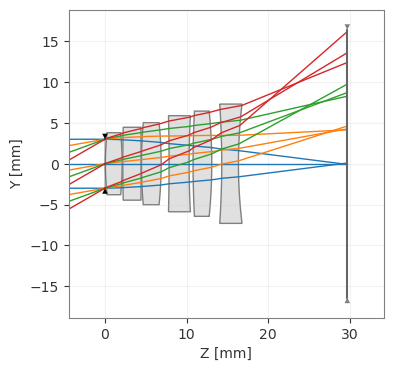

In [4]:
import base64, hashlib
project_bytes=base64.b64decode('ew0KICAic2NoZW1hVmVyc2lvbiI6IDEsDQogICJuYW1lIjogIk1vZGVyYXRlIFdpZGUgQW5nbGUgXHUwMGI3IGJvdW5kZWQgY2FuZGlkYXRlIDEiLA0KICAib2JqZWN0QXRJbmZpbml0eSI6IHRydWUsDQogICJmaWVsZFR5cGUiOiAiYW5nbGUiLA0KICAiZmllbGRzIjogWw0KICAgIDAuMCwNCiAgICAxMC4wLA0KICAgIDIwLjAsDQogICAgMzAuMA0KICBdLA0KICAicHJpbWFyeVdhdmVsZW5ndGgiOiAxLA0KICAiYXBlcnR1cmUiOiA2LjAsDQogICJyYXlBaW1pbmciOiB7DQogICAgIm1vZGUiOiAib2ZmIg0KICB9LA0KICAid2F2ZWxlbmd0aHMiOiBbDQogICAgew0KICAgICAgInZhbHVlIjogNDg2LjAsDQogICAgICAid2VpZ2h0IjogMS4wDQogICAgfSwNCiAgICB7DQogICAgICAidmFsdWUiOiA1ODguMCwNCiAgICAgICJ3ZWlnaHQiOiAxLjANCiAgICB9LA0KICAgIHsNCiAgICAgICJ2YWx1ZSI6IDY1Ni4wLA0KICAgICAgIndlaWdodCI6IDEuMA0KICAgIH0NCiAgXSwNCiAgImRlc2NyaXB0aW9uIjogIlNlbGYtY3JlYXRlZCB3ZWFrIHNwaGVyaWNhbCBzaW5nbGV0cyBmcm9tIHRoaW4tcG93ZXIgZXN0aW1hdGVzOyA2bW0gZmxhdCBlbnRyYW5jZSBzdG9wLiBQcm92aXNpb25hbCByZWZlcmVuY2Ugc2VlZCwgbm8gZ2FsbGVyeS9wcml2YXRlIHByZXNjcmlwdGlvbi4iLA0KICAic3VyZmFjZXMiOiBbDQogICAgew0KICAgICAgImlkIjogMCwNCiAgICAgICJ0eXBlIjogIm9iamVjdCIsDQogICAgICAicmFkaXVzIjogbnVsbCwNCiAgICAgICJ0aGlja25lc3MiOiBudWxsLA0KICAgICAgIm1hdGVyaWFsIjogIkFJUiIsDQogICAgICAic2VtaURpYW1ldGVyIjogMy4wLA0KICAgICAgImNvbmljIjogMC4wLA0KICAgICAgImFzcGhlcmUiOiBbXSwNCiAgICAgICJzdXJmYWNlVHlwZSI6ICJTVEFOREFSRCINCiAgICB9LA0KICAgIHsNCiAgICAgICJpZCI6IDEsDQogICAgICAidHlwZSI6ICJzdG9wIiwNCiAgICAgICJyYWRpdXMiOiBudWxsLA0KICAgICAgInRoaWNrbmVzcyI6IDAuMDUwMDAwMDAwMDAwMDAwMDEsDQogICAgICAibWF0ZXJpYWwiOiAiQUlSIiwNCiAgICAgICJzZW1pRGlhbWV0ZXIiOiAzLjAsDQogICAgICAiY29uaWMiOiAwLjAsDQogICAgICAiYXNwaGVyZSI6IFtdLA0KICAgICAgInN1cmZhY2VUeXBlIjogIlNUQU5EQVJEIg0KICAgIH0sDQogICAgew0KICAgICAgImlkIjogMiwNCiAgICAgICJ0eXBlIjogInN0YW5kYXJkIiwNCiAgICAgICJyYWRpdXMiOiAzNC45NTc1MzExNzEwMDEwNjUsDQogICAgICAidGhpY2tuZXNzIjogMi4wNTAwNTQ2OTg3Mzg0MywNCiAgICAgICJtYXRlcmlhbCI6ICJTQ0hPVFQ6Ti1CSzciLA0KICAgICAgInNlbWlEaWFtZXRlciI6IDMuNzk5MDEwNjI0NzUwODYzLA0KICAgICAgImNvbmljIjogMC4wLA0KICAgICAgImFzcGhlcmUiOiBbXSwNCiAgICAgICJzdXJmYWNlVHlwZSI6ICJTVEFOREFSRCINCiAgICB9LA0KICAgIHsNCiAgICAgICJpZCI6IDMsDQogICAgICAidHlwZSI6ICJzdGFuZGFyZCIsDQogICAgICAicmFkaXVzIjogLTM5LjY4NTU1NDAzNTk4ODA1LA0KICAgICAgInRoaWNrbmVzcyI6IDAuMDgzMTMyMDUxMjg5MDIxMjQsDQogICAgICAibWF0ZXJpYWwiOiAiQUlSIiwNCiAgICAgICJzZW1pRGlhbWV0ZXIiOiAzLjc5OTAxMDYyNDc1MDg2MywNCiAgICAgICJjb25pYyI6IDAuMCwNCiAgICAgICJhc3BoZXJlIjogW10sDQogICAgICAic3VyZmFjZVR5cGUiOiAiU1RBTkRBUkQiDQogICAgfSwNCiAgICB7DQogICAgICAiaWQiOiA0LA0KICAgICAgInR5cGUiOiAic3RhbmRhcmQiLA0KICAgICAgInJhZGl1cyI6IDIxMC4yNjU2MjUyMTE4OTIxNCwNCiAgICAgICJ0aGlja25lc3MiOiAyLjIzODc5NzQ2NTM5NzI5MywNCiAgICAgICJtYXRlcmlhbCI6ICJTQ0hPVFQ6RjIiLA0KICAgICAgInNlbWlEaWFtZXRlciI6IDQuNDY1MTY2NzcxMzA3NzU5LA0KICAgICAgImNvbmljIjogMC4wLA0KICAgICAgImFzcGhlcmUiOiBbXSwNCiAgICAgICJzdXJmYWNlVHlwZSI6ICJTVEFOREFSRCINCiAgICB9LA0KICAgIHsNCiAgICAgICJpZCI6IDUsDQogICAgICAidHlwZSI6ICJzdGFuZGFyZCIsDQogICAgICAicmFkaXVzIjogLTc0OC45NzM2MTcxOTc1Njk1LA0KICAgICAgInRoaWNrbmVzcyI6IDAuMDUwMDQxMTg0NjgyNjQ3MSwNCiAgICAgICJtYXRlcmlhbCI6ICJBSVIiLA0KICAgICAgInNlbWlEaWFtZXRlciI6IDQuNDY1MTY2NzcxMzA3NzU5LA0KICAgICAgImNvbmljIjogMC4wLA0KICAgICAgImFzcGhlcmUiOiBbXSwNCiAgICAgICJzdXJmYWNlVHlwZSI6ICJTVEFOREFSRCINCiAgICB9LA0KICAgIHsNCiAgICAgICJpZCI6IDYsDQogICAgICAidHlwZSI6ICJzdGFuZGFyZCIsDQogICAgICAicmFkaXVzIjogNTguMTY2ODY2ODkxODY1NzY2LA0KICAgICAgInRoaWNrbmVzcyI6IDIuNDA3NzIyMjM2Mjg3MjYyLA0KICAgICAgIm1hdGVyaWFsIjogIlNDSE9UVDpOLUJLNyIsDQogICAgICAic2VtaURpYW1ldGVyIjogNS4wMjQ1ODIyNDY5NzE4MjUsDQogICAgICAiY29uaWMiOiAwLjAsDQogICAgICAiYXNwaGVyZSI6IFtdLA0KICAgICAgInN1cmZhY2VUeXBlIjogIlNUQU5EQVJEIg0KICAgIH0sDQogICAgew0KICAgICAgImlkIjogNywNCiAgICAgICJ0eXBlIjogInN0YW5kYXJkIiwNCiAgICAgICJyYWRpdXMiOiAtNDkuODQwNTYyODE4NjM1MzMsDQogICAgICAidGhpY2tuZXNzIjogMC45NzI0OTUwMDU5MjE0NjcsDQogICAgICAibWF0ZXJpYWwiOiAiQUlSIiwNCiAgICAgICJzZW1pRGlhbWV0ZXIiOiA1LjAyNDU4MjI0Njk3MTgyNSwNCiAgICAgICJjb25pYyI6IDAuMCwNCiAgICAgICJhc3BoZXJlIjogW10sDQogICAgICAic3VyZmFjZVR5cGUiOiAiU1RBTkRBUkQiDQogICAgfSwNCiAgICB7DQogICAgICAiaWQiOiA4LA0KICAgICAgInR5cGUiOiAic3RhbmRhcmQiLA0KICAgICAgInJhZGl1cyI6IC0yNDYuNTI1MzUzMTY5NjU1NTIsDQogICAgICAidGhpY2tuZXNzIjogMi40NTYyMzg4NDExODAyNjg1LA0KICAgICAgIm1hdGVyaWFsIjogIlNDSE9UVDpGMiIsDQogICAgICAic2VtaURpYW1ldGVyIjogNS44ODYwODE4NDkyNjg0MDYsDQogICAgICAiY29uaWMiOiAwLjAsDQogICAgICAiYXNwaGVyZSI6IFtdLA0KICAgICAgInN1cmZhY2VUeXBlIjogIlNUQU5EQVJEIg0KICAgIH0sDQogICAgew0KICAgICAgImlkIjogOSwNCiAgICAgICJ0eXBlIjogInN0YW5kYXJkIiwNCiAgICAgICJyYWRpdXMiOiAxMTIuNDA0Mjg4NTMxNTExNTEsDQogICAgICAidGhpY2tuZXNzIjogMC40ODU1MjAwMjE3MzU5MDg3NSwNCiAgICAgICJtYXRlcmlhbCI6ICJBSVIiLA0KICAgICAgInNlbWlEaWFtZXRlciI6IDUuODg2MDgxODQ5MjY4NDA2LA0KICAgICAgImNvbmljIjogMC4wLA0KICAgICAgImFzcGhlcmUiOiBbXSwNCiAgICAgICJzdXJmYWNlVHlwZSI6ICJTVEFOREFSRCINCiAgICB9LA0KICAgIHsNCiAgICAgICJpZCI6IDEwLA0KICAgICAgInR5cGUiOiAic3RhbmRhcmQiLA0KICAgICAgInJhZGl1cyI6IDEyNC4zNTc5MzMyMjQwMjkzLA0KICAgICAgInRoaWNrbmVzcyI6IDIuMjg3ODE1NjI4MjQ0NTIzLA0KICAgICAgIm1hdGVyaWFsIjogIlNDSE9UVDpOLUJLNyIsDQogICAgICAic2VtaURpYW1ldGVyIjogNi40NDU5OTE5MjcyMzk1OTYsDQogICAgICAiY29uaWMiOiAwLjAsDQogICAgICAiYXNwaGVyZSI6IFtdLA0KICAgICAgInN1cmZhY2VUeXBlIjogIlNUQU5EQVJEIg0KICAgIH0sDQogICAgew0KICAgICAgImlkIjogMTEsDQogICAgICAidHlwZSI6ICJzdGFuZGFyZCIsDQogICAgICAicmFkaXVzIjogLTY2LjAwNzAyNDk5OTgwMjc3LA0KICAgICAgInRoaWNrbmVzcyI6IDEuMjIwOTQyNjU1MjIxMjUzNCwNCiAgICAgICJtYXRlcmlhbCI6ICJBSVIiLA0KICAgICAgInNlbWlEaWFtZXRlciI6IDYuNDQ1OTkxOTI3MjM5NTk2LA0KICAgICAgImNvbmljIjogMC4wLA0KICAgICAgImFzcGhlcmUiOiBbXSwNCiAgICAgICJzdXJmYWNlVHlwZSI6ICJTVEFOREFSRCINCiAgICB9LA0KICAgIHsNCiAgICAgICJpZCI6IDEyLA0KICAgICAgInR5cGUiOiAic3RhbmRhcmQiLA0KICAgICAgInJhZGl1cyI6IC0xMDkuNTcxNzU3NjM4NjczODYsDQogICAgICAidGhpY2tuZXNzIjogMi4wNTAzMTg2Mzg0ODYxODMsDQogICAgICAibWF0ZXJpYWwiOiAiU0NIT1RUOkYyIiwNCiAgICAgICJzZW1pRGlhbWV0ZXIiOiA3LjMwODg1MDA5NzMzOTAzMiwNCiAgICAgICJjb25pYyI6IDAuMCwNCiAgICAgICJhc3BoZXJlIjogW10sDQogICAgICAic3VyZmFjZVR5cGUiOiAiU1RBTkRBUkQiDQogICAgfSwNCiAgICB7DQogICAgICAiaWQiOiAxMywNCiAgICAgICJ0eXBlIjogInN0YW5kYXJkIiwNCiAgICAgICJyYWRpdXMiOiA2MS40OTE0ODQ3NzQzMTk3MTYsDQogICAgICAidGhpY2tuZXNzIjogMTMuMzM2NDUxNTY4NzI2NTEsDQogICAgICAibWF0ZXJpYWwiOiAiQUlSIiwNCiAgICAgICJzZW1pRGlhbWV0ZXIiOiA3LjMwODg1MDA5NzMzOTAzMiwNCiAgICAgICJjb25pYyI6IDAuMCwNCiAgICAgICJhc3BoZXJlIjogW10sDQogICAgICAic3VyZmFjZVR5cGUiOiAiU1RBTkRBUkQiDQogICAgfSwNCiAgICB7DQogICAgICAiaWQiOiAxNCwNCiAgICAgICJ0eXBlIjogImltYWdlIiwNCiAgICAgICJyYWRpdXMiOiBudWxsLA0KICAgICAgInRoaWNrbmVzcyI6IDAuMCwNCiAgICAgICJtYXRlcmlhbCI6ICJBSVIiLA0KICAgICAgInNlbWlEaWFtZXRlciI6IDE2LjQwOTI1MDAyMzA2ODAxNSwNCiAgICAgICJjb25pYyI6IDAuMCwNCiAgICAgICJhc3BoZXJlIjogW10sDQogICAgICAic3VyZmFjZVR5cGUiOiAiU1RBTkRBUkQiDQogICAgfQ0KICBdLA0KICAiYW5hbHlzaXMiOiB7DQogICAgIm10ZlNhbXBsZXMiOiA2NA0KICB9LA0KICAiZmllbGREZWZpbml0aW9ucyI6IFsNCiAgICB7DQogICAgICAieCI6IDAuMCwNCiAgICAgICJ5IjogMC4wLA0KICAgICAgIndlaWdodCI6IDEuMA0KICAgIH0sDQogICAgew0KICAgICAgIngiOiAwLjAsDQogICAgICAieSI6IDEwLjAsDQogICAgICAid2VpZ2h0IjogMS4wDQogICAgfSwNCiAgICB7DQogICAgICAieCI6IDAuMCwNCiAgICAgICJ5IjogMjAuMCwNCiAgICAgICJ3ZWlnaHQiOiAxLjANCiAgICB9LA0KICAgIHsNCiAgICAgICJ4IjogMC4wLA0KICAgICAgInkiOiAzMC4wLA0KICAgICAgIndlaWdodCI6IDEuMA0KICAgIH0NCiAgXSwNCiAgImZpZWxkV2VpZ2h0cyI6IFsNCiAgICAxLjAsDQogICAgMS4wLA0KICAgIDEuMCwNCiAgICAxLjANCiAgXSwNCiAgImZpZWxkVW5pdCI6ICJkZWciLA0KICAiYXBlcnR1cmVUeXBlIjogImVucGQiLA0KICAiYXBlcnR1cmVWYWx1ZSI6IDYuMCwNCiAgImFwb2RpemF0aW9uIjogew0KICAgICJ0eXBlIjogInVuaWZvcm0iLA0KICAgICJmYWN0b3IiOiAwLjANCiAgfSwNCiAgIm9iamVjdERpc3RhbmNlIjogbnVsbA0KfQ==')
assert hashlib.sha256(project_bytes).hexdigest()=='894652613d4c3dfe541a6dcd806a754470d5a42c44e0f42c9197156613e7fd79'
project=json.loads(project_bytes)

def build_lens(p):
    lens=Optic(name=p['name'])
    lens.surfaces.add(index=0,thickness=float('inf'))
    for i,s in enumerate(p['surfaces'][1:],1):
        material=IdealMaterial(1.) if s['material']=='AIR' else Material(
            s['material'].split(':')[1],catalog=s['material'].split(':')[0].lower(),match_policy=MatchPolicy.STRICT)
        lens.surfaces.add(index=i,radius=np.inf if s['radius'] is None else s['radius'],
            thickness=s['thickness'],material=material,is_stop=s['type']=='stop',
            conic=s['conic'],aperture=MatchedNumericalBoundary(s['semiDiameter']))
        lens.surfaces[-1].set_semi_aperture(s['semiDiameter'])
    lens.set_aperture(aperture_type='EPD',value=p['aperture'])
    lens.fields.set_type('angle')
    for f in p['fields']:lens.fields.add(y=f)
    for i,w in enumerate(p['wavelengths']):lens.wavelengths.add(
        value=w['value']/1000,weight=w['weight'],is_primary=i==p['primaryWavelength'])
    return lens

lens=build_lens(project)
display(pd.DataFrame(project['surfaces'])[['id','type','radius','thickness','material','semiDiameter']])
fig,ax=lens.draw(num_rays=3,show=False,figsize=(10,4))
plt.show()


## Fresh target-frequency evaluation and explicit rule gates

Run the same exact-20 lp/mm scalar pupil-overlap calculation on 256 and 512 point grids per axis. The declared local target sensitivity check is max absolute S/T difference <=2e-4 over all four fields; it is specific to this one frequency. Every calculation traces every interior ray, both continuous shifted-pupil overlaps, and a separate 128-angle full circumference for every field/color. No failed rays may be dropped. The complete set of nominal rule and additional solid-geometry gates is displayed below.


In [5]:
density=[]
for count in (256,512):
    result=native_scalar_mtf20(project,lens,samples=count,frequency=20.,continuous_shift=True)
    density.append(result)
native=density[-1]
audit=audit_nominal_project(project,native)
max_st_change=max(abs(a[k]-b[k]) for a,b in zip(density[0]['rows'],native['rows']) for k in ('sagittal20','tangential20'))
assert max_st_change<=2e-4, 'Target-frequency density sensitivity exceeds the declared local tolerance.'
assert audit['allPassed'] and audit['P']==0.
display(pd.DataFrame(audit['elements']))
display(pd.DataFrame(audit['checks']))
display(pd.DataFrame([{k:r[k] for k in ('fieldDeg','distortionFraction','sagittal20','tangential20','mean20','objectiveTerm')} for r in native['rows']]))
print(json.dumps({'LOCAL_M_NOT_OFFICIAL_SCORE':audit['localMerit'],'P':audit['P'],'eflMm':native['eflMm'],
    'fixedImageZMm':native['physicalImageZMm'],'physicalStopRadiusMm':native['physicalStopRadiusMm'],
    'maxST256to512':max_st_change,'targetSTTolerance':2e-4,
    'maxNeighborIndividualPupilPhaseWaves':max(s['maxNeighborPhaseWaves'] for r in native['rows'] for s in r['spectra']),
    'maxTarget20IntegrandPhaseStepWaves':max(max(s['maxTargetIntegrandPhaseStepWavesST']) for r in native['rows'] for s in r['spectra']),
    'maxChiefIncidenceDeg':max(s['chiefIncidenceDeg'] for r in native['rows'] for s in r['spectra']),
    'maxPupilMappingRmsFraction':max(s['pupilMappingRmsFraction'] for r in native['rows'] for s in r['spectra']),
    'individualPupilPhaseAliasWarningRetained':True,'fullPsfConvergenceClaimed':False},indent=2))
# A concrete invalid first-order value must produce a nonzero local penalty.
bad=dict(native,eflMm=23.)
assert audit_nominal_project(project,bad)['P']>0


,front,rear,material,ctMm,etMm,mechanicalRadiusMm
0,2,3,SCHOTT:N-BK7,2.050055,1.660759,3.799011
1,4,5,SCHOTT:F2,2.238797,2.178071,4.465167
2,6,7,SCHOTT:N-BK7,2.407722,1.936380,5.024582
3,8,9,SCHOTT:F2,2.456239,2.680736,5.886082
4,10,11,SCHOTT:N-BK7,2.287816,1.805143,6.445992
5,12,13,SCHOTT:F2,2.050319,2.730263,7.308850


,constraint,value,minimum,maximum,basis,passed,P
0,Infinite object,True,NaN,NaN,published rule,True,0.0
1,EFL / mm,23.999925,23.52,2.448000e+01,published rule,True,0.0
2,F-number,3.999988,3.80,4.200000e+00,published rule,True,0.0
3,Physical elements,6,5.00,8.000000e+00,published rule,True,0.0
4,Spherical only,True,NaN,NaN,published rule,True,0.0
5,Supported catalogs,True,NaN,NaN,published rule,True,0.0
6,Fields / degrees,"[0.0, 10.0, 20.0, 30.0]",NaN,NaN,published rule,True,0.0
7,Full field of view / degrees,60.0,60.00,NaN,published rule,True,0.0
8,Exact equal spectrum,True,NaN,NaN,published rule,True,0.0
9,Primary wavelength and field weights,True,NaN,NaN,local convention,True,0.0


,fieldDeg,distortionFraction,sagittal20,tangential20,mean20,objectiveTerm
0,0.0,0.000000,0.048847,0.048847,0.048847,0.904691
1,10.0,0.008960,0.000427,0.007535,0.003981,1.192741
2,20.0,-0.001655,0.000255,0.001369,0.000812,1.005221
3,30.0,-0.018763,0.000236,0.000417,0.000326,1.879514


{
  "LOCAL_M_NOT_OFFICIAL_SCORE": 4.982166755940591,
  "P": 0.0,
  "eflMm": 23.999925260715507,
  "fixedImageZMm": 29.689529995910767,
  "physicalStopRadiusMm": 3.0,
  "maxST256to512": 0.0001096691105741223,
  "targetSTTolerance": 0.0002,
  "maxNeighborIndividualPupilPhaseWaves": 1.6827176226255744,
  "maxTarget20IntegrandPhaseStepWaves": 0.1522856361991387,
  "maxChiefIncidenceDeg": 31.093973382335143,
  "maxPupilMappingRmsFraction": 0.01189623315552119,
  "individualPupilPhaseAliasWarningRetained": true,
  "fullPsfConvergenceClaimed": false
}


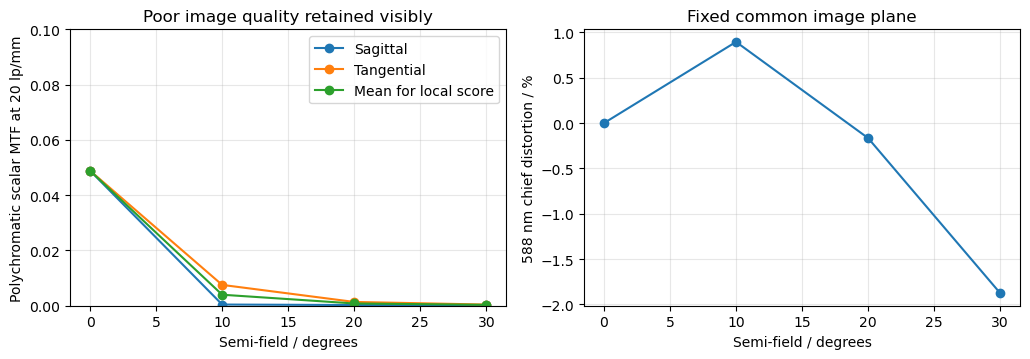

In [6]:
fig,axes=plt.subplots(1,2,figsize=(10.4,3.7))
for key,label in [('sagittal20','Sagittal'),('tangential20','Tangential'),('mean20','Mean for local score')]:
    axes[0].plot([r['fieldDeg'] for r in native['rows']],[r[key] for r in native['rows']],'o-',label=label)
axes[0].set(xlabel='Semi-field / degrees',ylabel='Polychromatic scalar MTF at 20 lp/mm',title='Poor image quality retained visibly',ylim=(0,.1));axes[0].legend()
axes[1].plot([r['fieldDeg'] for r in native['rows']],[100*r['distortionFraction'] for r in native['rows']],'o-')
axes[1].set(xlabel='Semi-field / degrees',ylabel='588 nm chief distortion / %',title='Fixed common image plane')
for ax in axes:ax.grid(True,alpha=.3)
fig.tight_layout();plt.show()


## Supplementary independent records and attribution

Supplementary development records are published alongside this notebook: [independent numerical and geometry audit](independent-final-validation.json), [constraint tests](independent-test-summary.json), and [source-stage selection](selection.json). These separate records include ray comparison, positive/negative constraint tests and the target-frequency density decision. They are not dependencies of the fresh calculations above. The prescribed raw JSON bytes are SHA-256 checked in this notebook. The original project description retained in that byte-frozen record describes its seed; the frozen prescription table above contains the subsequently conditioned numerical candidate.

The accepted seed was self-created from weak spherical singlet power estimates. Optiland is pinned to `a9e544a2e058f1c1b64606e9ce90e6dc103efee1`; standalone-optics sources are pinned to `d130999165abc8ccc1865c4ef145cd6bda191a4d` and hash checked individually. No new license is assigned to standalone-optics here. Optiland's upstream MIT notice follows.


```text
MIT License

Copyright (c) 2024 Kramer Harrison

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

```